# Validation/Evaluation
1. Compare model performances (ROC AUC)
2. Most relevant feature (using permutation_importance)
3. Logistic regression + log explanations
4. EBM explanations
5. XGBoost explanations

NumPy: 2.4.6
pandas: 3.1.1
Number of rows: 319
Number of columns: 39
Dataset shape: (319, 39)
Dataset datatypes:
Gallstone Status                                    int64
Age                                                 int64
Gender                                              int64
Comorbidity                                         int64
Coronary Artery Disease (CAD)                       int64
Hypothyroidism                                      int64
Hyperlipidemia                                      int64
Diabetes Mellitus (DM)                              int64
Height                                              int64
Weight                                            float64
Body Mass Index (BMI)                             float64
Total Body Water (TBW)                            float64
Extracellular Water (ECW)                         float64
Intracellular Water (ICW)                         float64
Extracellular Fluid/Total Body Water (ECF/TBW)    float64
Total Body Fat Ra

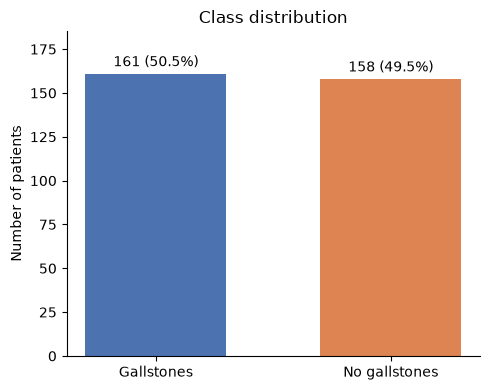

Gallstone Status  Gallstones  No gallstones
Gender                                     
Male                      94             68
Female                    67             90


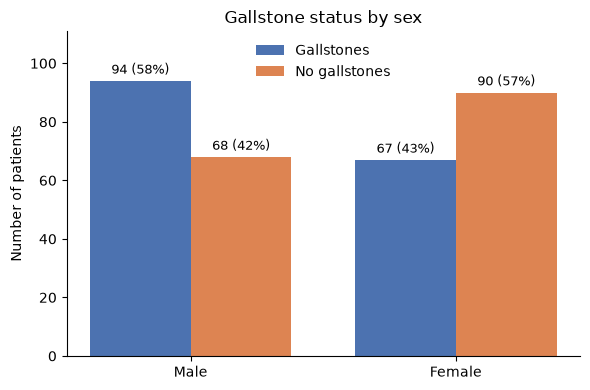

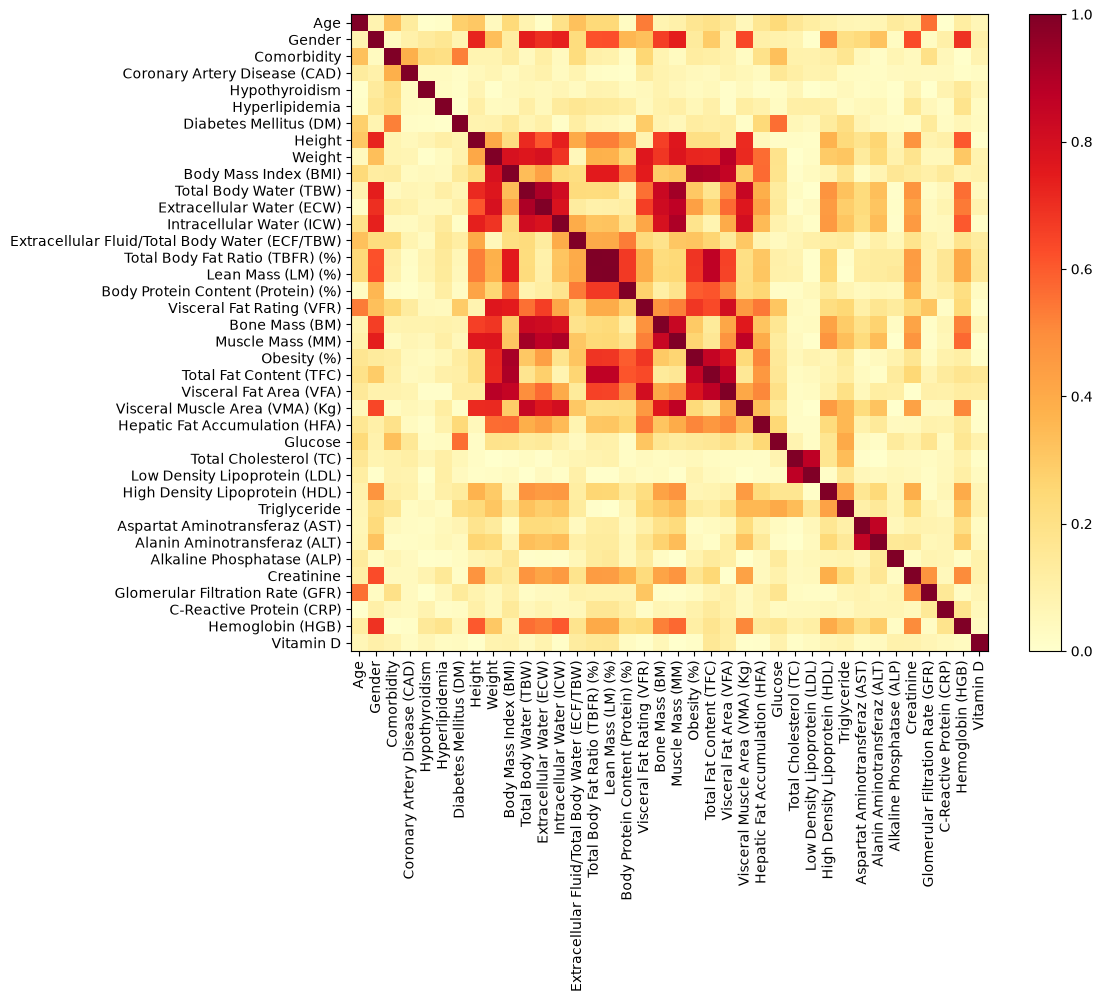

Dropped 5: ['Extracellular Water (ECW)', 'Lean Mass (LM) (%)', 'Muscle Mass (MM)', 'Obesity (%)', 'Total Fat Content (TFC)']
0      0
1      0
2      0
3      0
4      0
      ..
313    1
314    1
315    1
316    1
317    1
Name: Gallstone Status, Length: 317, dtype: int64
NumPy: 2.4.6
pandas: 3.1.1
Train: (253, 33), Test: (64, 33)

=== logreg ===
{'C': 0.001}
    accuracy: 0.664 ± 0.061  roc_auc: 0.743 ± 0.070  f1: 0.629 ± 0.084
{'C': 0.01}
    accuracy: 0.728 ± 0.064  roc_auc: 0.805 ± 0.081  f1: 0.708 ± 0.081
{'C': 0.1}
    accuracy: 0.763 ± 0.074  roc_auc: 0.845 ± 0.075  f1: 0.741 ± 0.094
{'C': 1}
    accuracy: 0.787 ± 0.044  roc_auc: 0.871 ± 0.053  f1: 0.775 ± 0.055
{'C': 10}
    accuracy: 0.807 ± 0.033  roc_auc: 0.877 ± 0.046  f1: 0.802 ± 0.034
{'C': 100}
    accuracy: 0.811 ± 0.028  roc_auc: 0.869 ± 0.049  f1: 0.806 ± 0.031
{'C': 1000}
    accuracy: 0.811 ± 0.028  roc_auc: 0.867 ± 0.050  f1: 0.806 ± 0.031
Best (by CV ROC AUC): {'C': 10} -> 0.877

=== logreg + log ===
{'C': 0.001}

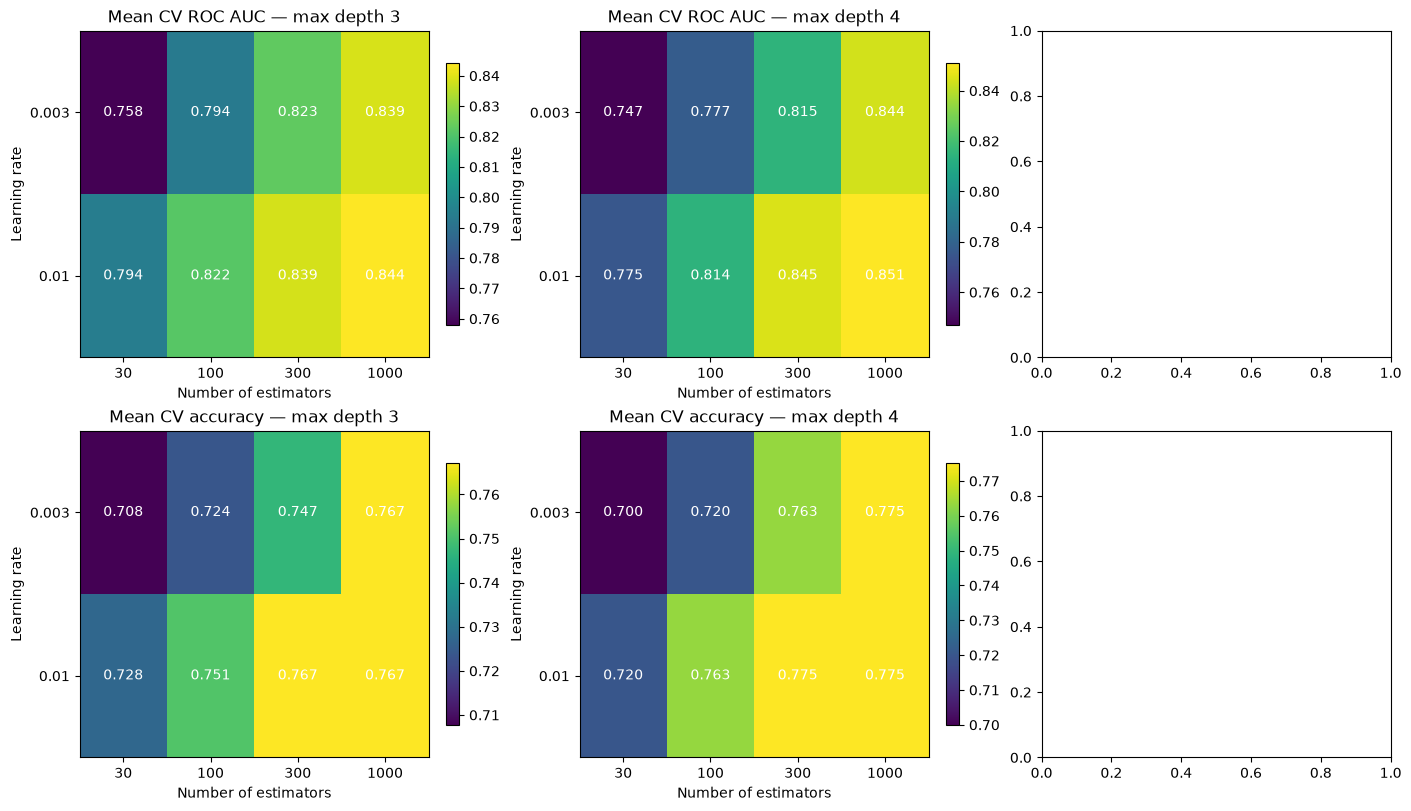

In [ ]:
%run ./2_model_selection.ipynb

# 1. Compare model performances (ROC AUC)
Every model is rebuilt with the best hyperparameters found in `2_` and then:
- scored with **repeated stratified 5-fold CV (5 × 5 = 25 folds)** on the training set, which gives a stable mean ± std, and
- fitted once on the full training set and evaluated **once** on the 20% test set.

**Label coding:** `Gallstone Status` is 0 = gallstones present, 1 = absent, so `predict_proba(...)[:, 1]` is the probability of **not** having gallstones. ROC AUC does not depend on which class is called positive. Precision, recall and F1 are reported for the clinically relevant class, **gallstones present (label 0)**: recall is the share of gallstone patients the model identifies.

In [ ]:
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, confusion_matrix,
                             precision_score, recall_score)

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)

final_models = {name: make_model(name, **params) for name, params in best_params.items()}

rows, fitted, probas = [], {}, {}
for name, model in final_models.items():
    # Validation: repeated CV on the training set only
    s = cross_val_score(model, X_train, y_train, cv=rcv, scoring="roc_auc")

    # Test: fit once on the full training set, evaluate once
    m = clone(model).fit(X_train, y_train)
    fitted[name] = m
    p = m.predict_proba(X_test)[:, 1]          # P(label 1) = P(no gallstones)
    pred = (p >= 0.5).astype(int)
    probas[name] = p

    rows.append({
        "Model": name,
        "CV ROC AUC": s.mean(), "CV ROC AUC std": s.std(),
        "Test ROC AUC": roc_auc_score(y_test, p),
        "Test accuracy": accuracy_score(y_test, pred),
        # precision / recall / F1 for gallstones present (label 0)
        "Test precision (gallstones)": precision_score(y_test, pred, pos_label=0),
        "Test recall (gallstones)": recall_score(y_test, pred, pos_label=0),
        "Test F1 (gallstones)": f1_score(y_test, pred, pos_label=0),
    })

results = pd.DataFrame(rows).set_index("Model").sort_values("CV ROC AUC", ascending=False)
results.round(3)

In [ ]:
# Same table formatted for the LaTeX report
latex = pd.DataFrame({
    "CV ROC AUC": [f"${r['CV ROC AUC']:.3f} \\pm {r['CV ROC AUC std']:.3f}$" for _, r in results.iterrows()],
    "Test ROC AUC": results["Test ROC AUC"].map("{:.3f}".format),
    "Test accuracy": results["Test accuracy"].map("{:.3f}".format),
}, index=results.index).reset_index()
print(latex.to_latex(index=False, column_format="lccc"))

In [ ]:
fig, axes = plt.subplots(1, len(fitted) + 1, figsize=(5 * (len(fitted) + 1), 4.5))

for ax, (name, m) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (probas[name] >= 0.5).astype(int)),
                           display_labels=["0: gallstones", "1: none"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion matrix: {name}")

for name, p in probas.items():
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=axes[-1])
axes[-1].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[-1].set_title("ROC curves (test set)")
plt.tight_layout()
plt.show()

# 2. Most relevant features (permutation importance)
For each model and each of the 25 CV folds: train on the other folds, then shuffle one feature at a time in the held-out fold and measure how much ROC AUC drops. `top5_rate` is the share of folds in which a feature ranked among the 5 most important. Features that rank high for **all** models are the most trustworthy findings.

In [ ]:
summaries = {}
for name, model in final_models.items():
    fold_imp = []
    for tr, va in rcv.split(X_train, y_train):
        m = clone(model).fit(X_train.iloc[tr], y_train.iloc[tr])
        r = permutation_importance(m, X_train.iloc[va], y_train.iloc[va],
                                   scoring="roc_auc", n_repeats=10, random_state=42)
        fold_imp.append(r.importances_mean)

    imp = pd.DataFrame(fold_imp, columns=X_train.columns)
    summaries[name] = pd.DataFrame({
        "mean": imp.mean(),
        "std": imp.std(),
        "top5_rate": (imp.rank(axis=1, ascending=False) <= 5).mean(),
    }).sort_values("mean", ascending=False)
    print(f"\n{name}")
    print(summaries[name].head(10).round(3))

In [ ]:
# How often each feature is in the top 5, per model (sorted by the total over all models)
top5 = pd.DataFrame({name: s["top5_rate"] for name, s in summaries.items()})
top5["Sum"] = top5.sum(axis=1)
top5 = top5.sort_values("Sum", ascending=False)
display(top5.head(10).round(2))
print(top5.head(10).to_latex(float_format="%.2f"))

# 3. Logistic regression + log explanations
Logistic regression is also a glass-box model. Its prediction is the intercept plus one contribution per feature, $w_j \cdot z_j$, where $z_j$ is the (log-transformed and) standardized feature value. As for the EBM, the model predicts label 1 (**no** gallstones), so a contribution **below 0 raises the gallstone risk**.
- **Coefficients:** the sign and size of each weight. Because the features are standardized, the weights are comparable. Features are ranked by their mean absolute contribution, the same measure as the EBM's term importance.
- **Feature effects:** the contribution of a feature as a function of its raw value. It is a straight line for untransformed features and a log curve for log-transformed ones; compare these with the EBM's learned shape functions.
- **Local explanation:** the exact per-feature breakdown of one patient's prediction.

In [ ]:
lr_pipe = fitted["logreg + log"]
lr_pre = lr_pipe[:-1]                  # log transform + standardization
lr_clf = lr_pipe[-1]

# Column order after the ColumnTransformer: log-transformed features first, then the rest
lr_names = []
for _, trans, cols in lr_pipe[0].transformers_:
    if isinstance(trans, str) and trans == "drop":
        continue
    lr_names += [X_train.columns[c] if isinstance(c, (int, np.integer)) else c for c in cols]

lr_coef = pd.Series(lr_clf.coef_[0], index=lr_names)
Z_train = pd.DataFrame(lr_pre.transform(X_train), columns=lr_names, index=X_train.index)
lr_imp = (Z_train * lr_coef).abs().mean().sort_values()   # mean |contribution|

top = lr_coef[lr_imp.tail(15).index]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color=["tab:red" if v < 0 else "tab:green" for v in top.values])
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("coefficient on standardized feature (red = higher gallstone risk)")
plt.title("Logistic regression + log: 15 most important features")
plt.tight_layout()
plt.show()

In [ ]:
lr_scaler = lr_pipe[1]
lr_mean = pd.Series(lr_scaler.mean_, index=lr_names)
lr_scale = pd.Series(lr_scaler.scale_, index=lr_names)
log_cols = set(skewed)

def lr_effect(feature, x):
    """Contribution w_j * z_j of a feature at raw value(s) x."""
    t = np.log1p(x) if feature in log_cols else x
    return lr_coef[feature] * (t - lr_mean[feature]) / lr_scale[feature]

lr_top6 = lr_imp.sort_values(ascending=False).index[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for f, ax in zip(lr_top6, axes.ravel()):
    vals = X_train[f]
    if vals.nunique() <= 2:                       # binary feature: one bar per value
        cats = sorted(vals.unique())
        ax.bar([str(c) for c in cats], [lr_effect(f, c) for c in cats])
    else:                                         # continuous feature: line / log curve
        grid = np.linspace(vals.min(), vals.max(), 200)
        ax.plot(grid, lr_effect(f, grid))
        ax.plot(vals, np.full(len(vals), ax.get_ylim()[0]), "|", color="k", alpha=0.3)  # data points
    ax.axhline(0, color="k", lw=0.8, ls="--")
    ax.set_title(f + (" (log-transformed)" if f in log_cols else ""), fontsize=9)
    ax.set_ylabel("contribution (< 0 = higher gallstone risk)")
plt.suptitle("Logistic regression + log: effect of the 6 most important features")
plt.tight_layout()
plt.show()

In [ ]:
# Explain one misclassified test patient
p_lr = probas["logreg + log"]
wrong = np.where((p_lr >= 0.5).astype(int) != y_test.to_numpy())[0]
i = int(wrong[0]) if len(wrong) else 0

z = pd.Series(lr_pre.transform(X_test.iloc[[i]])[0], index=lr_names)
contrib = z * lr_coef
contrib = contrib.reindex(contrib.abs().sort_values().index).tail(10)

plt.figure(figsize=(8, 5))
# Negative contributions push towards label 0 (gallstones present)
plt.barh(contrib.index, contrib.values, color=["tab:red" if v < 0 else "tab:green" for v in contrib.values])
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("contribution to log-odds of no gallstones (red = towards gallstones)")
plt.title(f"Test patient {X_test.index[i]}: true = {'gallstones' if y_test.iloc[i] == 0 else 'none'}, "
          f"P(gallstones) = {1 - p_lr[i]:.2f}")
plt.tight_layout()
plt.show()

# 4. EBM explanations
The EBM is a glass-box model, so besides permutation importance we can look directly inside it:
- **Term importance:** the mean absolute contribution of each feature (or interaction) to the log-odds.
- **Shape functions:** how each feature changes the prediction. The EBM models the log-odds of label 1 (**no** gallstones), so a value **below 0 raises the gallstone risk** and a value above 0 lowers it. The shaded band is the uncertainty across the EBM's bagged models.
- **Local explanation:** the exact per-feature breakdown of one patient's prediction.

In [ ]:
ebm = fitted["ebm"]
term_imp = pd.Series(ebm.term_importances(), index=ebm.term_names_).sort_values()

top = term_imp.tail(15)
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color=["tab:orange" if " & " in t else "tab:blue" for t in top.index])
plt.xlabel("Mean |contribution| to log-odds")
plt.title("EBM term importance (orange = interaction)")
plt.tight_layout()
plt.show()

In [ ]:
glob = ebm.explain_global()
term_index = {t: i for i, t in enumerate(ebm.term_names_)}

def plot_shape(term, ax):
    d = glob.data(term_index[term])
    scores, names = np.asarray(d["scores"]), d["names"]
    lo, hi = d.get("lower_bounds"), d.get("upper_bounds")
    if len(names) == len(scores) + 1:      # continuous feature: names are bin edges
        edges = np.asarray(names, dtype=float)
        ax.step(edges, np.r_[scores, scores[-1]], where="post")
        if lo is not None and hi is not None:
            ax.fill_between(edges, np.r_[lo, lo[-1]], np.r_[hi, hi[-1]], step="post", alpha=0.2)
    else:                                  # nominal feature: one bar per category
        ax.bar([str(n) for n in names], scores)
    ax.axhline(0, color="k", lw=0.8, ls="--")
    ax.set_title(term, fontsize=9)
    ax.set_ylabel("contribution (< 0 = higher gallstone risk)")

main_terms = [t for t in term_imp.sort_values(ascending=False).index if " & " not in t][:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for t, ax in zip(main_terms, axes.ravel()):
    plot_shape(t, ax)
plt.suptitle("EBM shape functions of the 6 most important features")
plt.tight_layout()
plt.show()

In [ ]:
# Explain one misclassified test patient: which features pushed the prediction the wrong way?
p_ebm = probas["ebm"]
wrong = np.where((p_ebm >= 0.5).astype(int) != y_test.to_numpy())[0]
i = int(wrong[0]) if len(wrong) else 0

d = ebm.explain_local(X_test.iloc[[i]], y_test.iloc[[i]]).data(0)
contrib = pd.Series(d["scores"], index=d["names"])
contrib = contrib.reindex(contrib.abs().sort_values().index).tail(10)

plt.figure(figsize=(8, 5))
# Negative contributions push towards label 0 (gallstones present)
plt.barh(contrib.index, contrib.values, color=["tab:red" if v < 0 else "tab:green" for v in contrib.values])
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("contribution to log-odds of no gallstones (red = towards gallstones)")
plt.title(f"Test patient {X_test.index[i]}: true = {'gallstones' if y_test.iloc[i] == 0 else 'none'}, P(gallstones) = {1 - p_ebm[i]:.2f}")
plt.tight_layout()
plt.show()

# 5. XGBoost explanations
XGBoost is a black box: its prediction is the sum of hundreds of trees, which cannot be read directly. It can still be explained with **SHAP values**, which split each prediction into one contribution per feature, so that prediction = base value + sum of contributions (on the log-odds scale, like the EBM). For tree models SHAP values are computed exactly (TreeSHAP), and XGBoost has this built in (`pred_contribs=True`), so no extra package is needed. The model predicts label 1 (**no** gallstones), so a contribution **below 0 raises the gallstone risk**.
- **Importance:** the mean absolute SHAP value of each feature, comparable to the EBM's term importance.
- **Dependence plots:** the SHAP value of a feature against its value, one dot per training patient. This is the black-box counterpart of the EBM's shape functions. A vertical spread at the same feature value means the effect depends on other features (interactions).
- **Local explanation:** the per-feature breakdown of one patient's prediction.

In [ ]:
import xgboost as xgb

booster = fitted["xgboost"].get_booster()
shap_train = booster.predict(xgb.DMatrix(X_train), pred_contribs=True)   # last column = base value
xgb_shap = pd.DataFrame(shap_train[:, :-1], columns=X_train.columns, index=X_train.index)
xgb_imp = xgb_shap.abs().mean().sort_values()

top = xgb_imp.tail(15)
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values)
plt.xlabel("Mean |SHAP value| (log-odds)")
plt.title("XGBoost: 15 most important features (SHAP)")
plt.tight_layout()
plt.show()

In [ ]:
xgb_top6 = xgb_imp.sort_values(ascending=False).index[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for f, ax in zip(xgb_top6, axes.ravel()):
    ax.scatter(X_train[f], xgb_shap[f], s=12, alpha=0.6)
    ax.axhline(0, color="k", lw=0.8, ls="--")
    ax.set_title(f, fontsize=9)
    ax.set_xlabel("feature value")
    ax.set_ylabel("SHAP value (< 0 = higher gallstone risk)")
plt.suptitle("XGBoost: SHAP dependence of the 6 most important features")
plt.tight_layout()
plt.show()

In [ ]:
# Explain one misclassified test patient
p_xgb = probas["xgboost"]
wrong = np.where((p_xgb >= 0.5).astype(int) != y_test.to_numpy())[0]
i = int(wrong[0]) if len(wrong) else 0

shap_i = booster.predict(xgb.DMatrix(X_test.iloc[[i]]), pred_contribs=True)[0, :-1]
contrib = pd.Series(shap_i, index=X_test.columns)
contrib = contrib.reindex(contrib.abs().sort_values().index).tail(10)

plt.figure(figsize=(8, 5))
# Negative contributions push towards label 0 (gallstones present)
plt.barh(contrib.index, contrib.values, color=["tab:red" if v < 0 else "tab:green" for v in contrib.values])
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("SHAP value, log-odds of no gallstones (red = towards gallstones)")
plt.title(f"Test patient {X_test.index[i]}: true = {'gallstones' if y_test.iloc[i] == 0 else 'none'}, "
          f"P(gallstones) = {1 - p_xgb[i]:.2f}")
plt.tight_layout()
plt.show()